<a href="https://colab.research.google.com/github/bavucadoz/244107020162_ML_2026/blob/main/Minggu09/TG9_1_244107020162_AryaBayuSamodra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas 1**


---



1.
Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara `male` dan `female` pada dataset `voice.csv`.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving voice.csv to voice.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('voice.csv')
df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male




---

2.
Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?


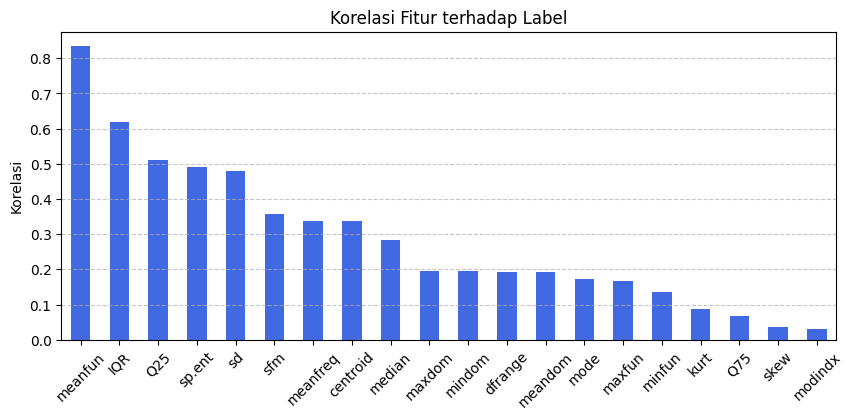

In [3]:
# Encode label jadi angka
df['label_num'] = df['label'].map({'male': 1, 'female': 0})

# Cek korelasi fitur ke label
korelasi = df.drop('label', axis=1).corr()['label_num'].abs().sort_values(ascending=False)

plt.figure(figsize=(10, 4))
korelasi.drop('label_num').plot(kind='bar', color='royalblue')
plt.title('Korelasi Fitur terhadap Label')
plt.ylabel('Korelasi')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X_all = df.drop(['label', 'label_num'], axis=1)
y = df['label_num']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_all, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_all = scaler.fit_transform(X_train_raw)
X_test_all = scaler.transform(X_test_raw)

# Baseline semua fitur
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_all, y_train)
acc_all = accuracy_score(y_test, knn.predict(X_test_all))

# Membandingkan beberapa jumlah fitur teratas
hasil = []
for n in [3, 5, 7, 10, 20]:
    if n == 20:
        cols = list(X_all.columns)
        acc = acc_all
    else:
        cols = list(korelasi.index[1:n+1])
        X_tr = scaler.fit_transform(X_train_raw[cols])
        X_te = scaler.transform(X_test_raw[cols])
        knn = KNeighborsClassifier(n_neighbors=5)
        knn.fit(X_tr, y_train)
        acc = accuracy_score(y_test, knn.predict(X_te))
    hasil.append({'Fitur': f'{n} Fitur', 'Akurasi (k=5)': f'{acc * 100:.2f}%', 'Contoh Fitur': ', '.join(cols[:4])})

pd.DataFrame(hasil)

,Fitur,Akurasi (k=5),Contoh Fitur
0,3 Fitur,97.95%,"meanfun, IQR, Q25"
1,5 Fitur,97.95%,"meanfun, IQR, Q25, sp.ent"
2,7 Fitur,98.42%,"meanfun, IQR, Q25, sp.ent"
3,10 Fitur,98.58%,"meanfun, IQR, Q25, sp.ent"
4,20 Fitur,98.11%,"meanfreq, sd, median, Q25"


In [8]:
fitur_pilihan = list(korelasi.index[1:11])
print("Fitur yang dipakai:", fitur_pilihan)

Fitur yang dipakai: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm', 'meanfreq', 'centroid', 'median', 'maxdom']


= Dari percobaan, kita pakai 10 fitur teratas berdasarkan nilai korelasinya. Fitur meanfun dan IQR, adalah fitur yang paling berpengaruh karena nada dasar suara perempuan dan laki-laki memang berbeda secara alami. Dengan menggunakan 10 fitur, akurasinya meningkat jadi 98.58% dibandingkan memakai 3 fitur, 5 fitur, 7 fitur, dan 20 fitur.



---
3.
Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.



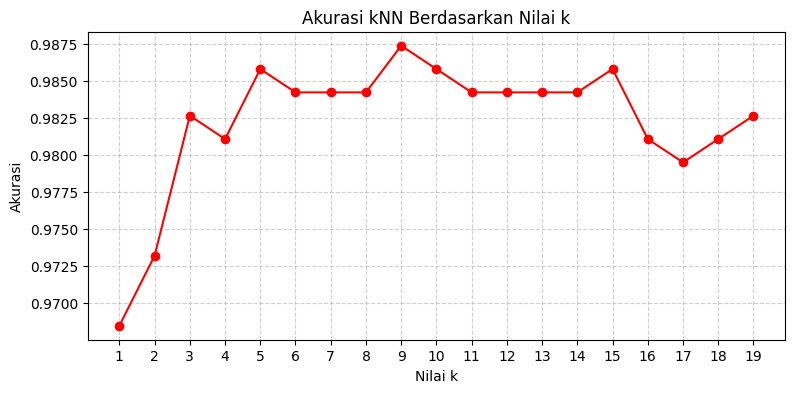

Nilai k terbaik: k = 9 (Akurasi: 98.74%)


In [12]:
X_pilihan = df[fitur_pilihan]
X_train_p, X_test_p, y_train, y_test = train_test_split(X_pilihan, y, test_size=0.2, random_state=42)

X_train_p = scaler.fit_transform(X_train_p)
X_test_p = scaler.transform(X_test_p)

k_list = range(1, 20)
akurasi = []

for k in k_list:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_p, y_train)
    akurasi.append(accuracy_score(y_test, model.predict(X_test_p)))

plt.figure(figsize=(9, 4))
plt.plot(k_list, akurasi, marker='o', color='red')
plt.title('Akurasi kNN Berdasarkan Nilai k')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.xticks(k_list)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

k_terbaik = k_list[np.argmax(akurasi)]
print(f"Nilai k terbaik: k = {k_terbaik} (Akurasi: {max(akurasi) * 100:.2f}%)")

= Berdasarkan grafik pengujian kNN dengan 10 fitur tersebut, nilai parameter $k=9$ terpilih sebagai yang paling optimal karena berhasil mencapai titik puncak akurasi tertinggi sebesar 98,74%. Pada nilai $k$ yang sangat kecil seperti $k=1$, model terindikasi mengalami overfitting karena terlalu sensitif terhadap noise sehingga menghasilkan akurasi terendah di bawah 0,9700. Seiring bertambahnya jumlah tetangga, kemampuan generalisasi model membaik hingga menemukan titik keseimbangan di $k=9$, sebelum akhirnya performa kembali merosot tajam pada $k=16$ dan $k=17$ akibat underfitting di mana batas wilayah keputusan antarkelas menjadi terlalu luas dan buram.